In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

paths = [Path("../data/airbnb_london.csv"), Path("data/airbnb_london.csv"),
         Path("airbnb_london.csv"), Path("listings-28.csv")]
data_path = next((p for p in paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("London listings CSV not found.")
df = pd.read_csv(data_path, low_memory=False)

def clean_num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[$£€,]", "", regex=True).str.strip(), errors="coerce")

work = df.copy()
for c in ["price", "availability_365", "reviews_per_month", "accommodates"]:
    work[c] = clean_num(work[c])
work = work[(work.price > 0) & work.room_type.notna()]
work = work[work.price <= work.price.quantile(0.95)]
work["price_per_guest"] = work.price / work.accommodates.replace(0, np.nan)


room_type,listings,median_price,median_price_per_guest,median_availability,median_reviews_per_month
Entire home/apt,37724,217.00,58.34,248.0,0.86
Hotel room,121,148.00,68.50,348.0,0.18
Private room,18901,80.00,46.50,259.0,0.87
Shared room,163,35.42,26.00,328.0,1.05


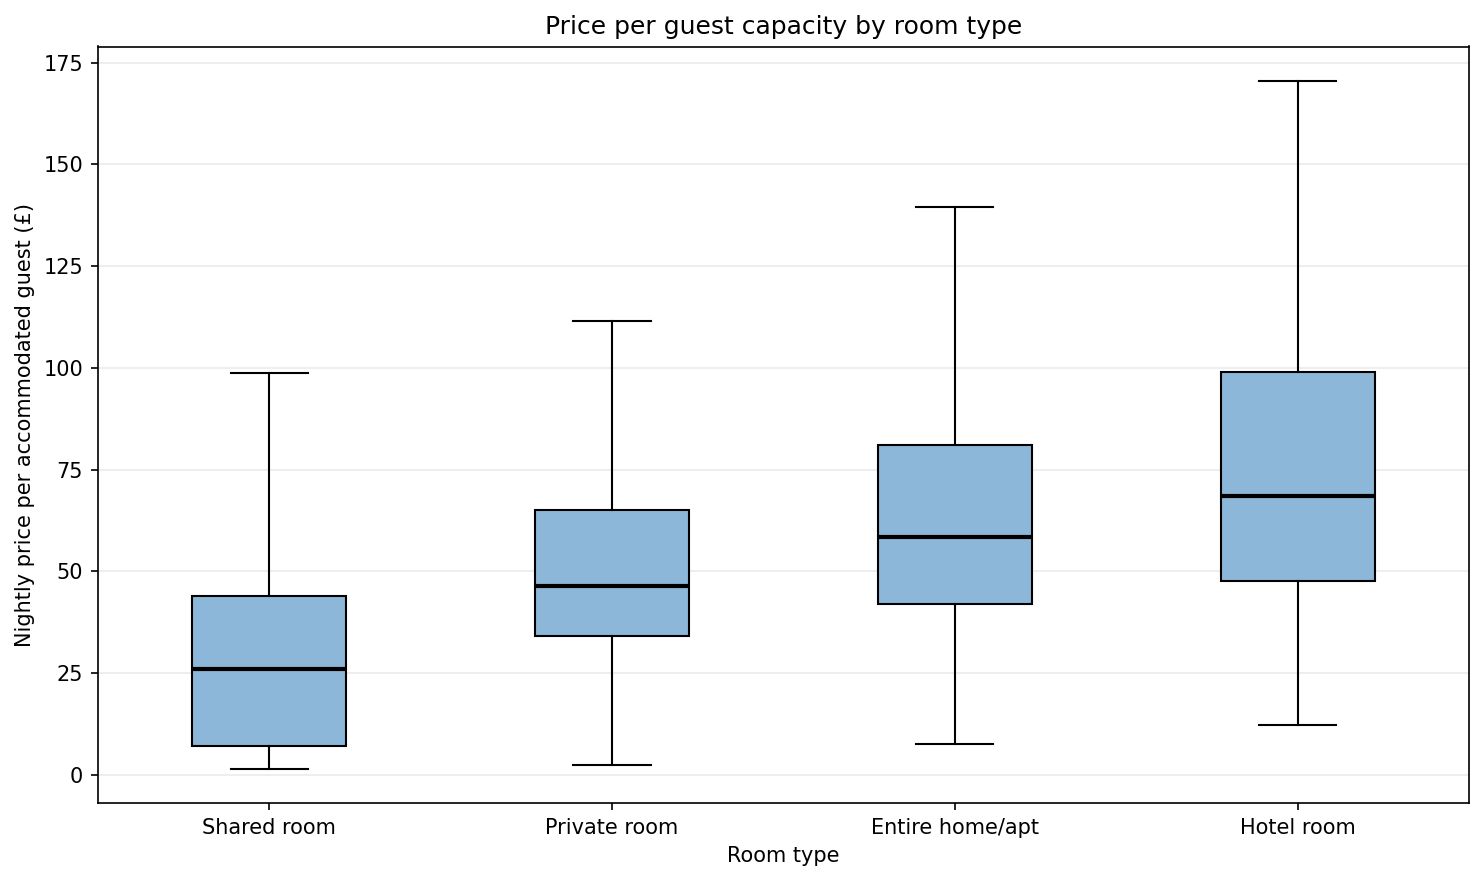

In [2]:
room_summary = work.groupby("room_type").agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    median_price_per_guest=("price_per_guest", "median"),
    median_availability=("availability_365", "median"),
    median_reviews_per_month=("reviews_per_month", "median")
).round(2).reset_index()
display(room_summary)

plot_data = work.dropna(subset=["price_per_guest"])
room_order = plot_data.groupby("room_type").price_per_guest.median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot([plot_data.loc[plot_data.room_type == r, "price_per_guest"].values for r in room_order],
                tick_labels=room_order, patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor("#8DB7D8")
ax.set_title("Price per guest capacity by room type")
ax.set_xlabel("Room type")
ax.set_ylabel("Nightly price per accommodated guest (£)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


room_type,availability_band,listings,median_price
Entire home/apt,0–30,2982,196.88
Entire home/apt,31–90,5451,207.00
Entire home/apt,91–180,6533,212.00
Entire home/apt,181–270,6584,215.00
Entire home/apt,271–365,16174,226.72
Hotel room,0–30,4,165.00
Hotel room,31–90,10,233.00
Hotel room,91–180,4,265.00
Hotel room,181–270,8,101.00
Hotel room,271–365,95,148.00


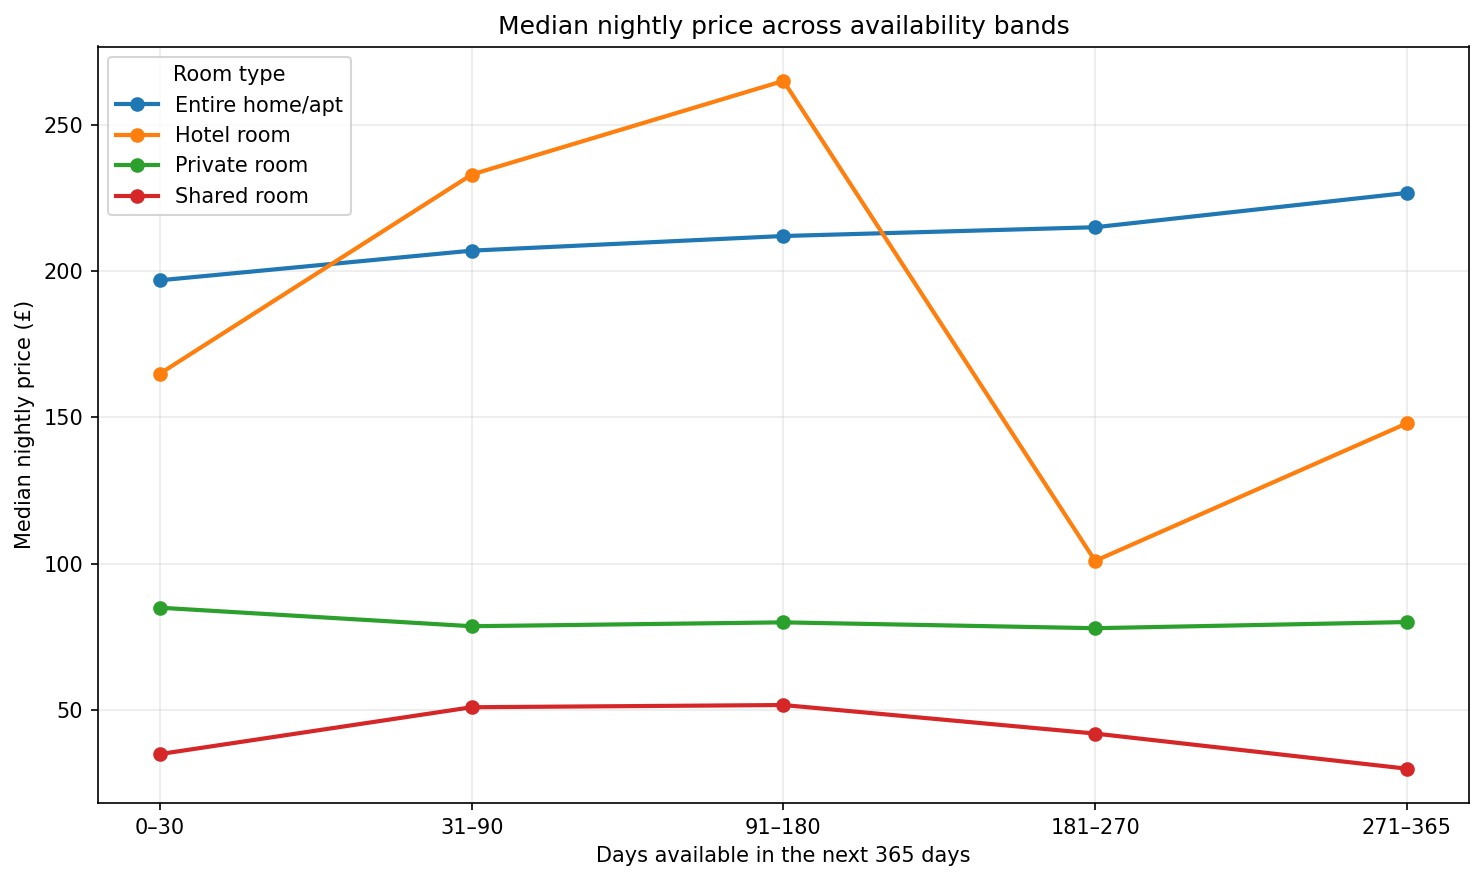

In [3]:
availability_data = work.dropna(subset=["availability_365", "price"]).copy()
availability_data = availability_data[availability_data.availability_365.between(0, 365)]
bins = [-1, 30, 90, 180, 270, 365]
labels = ["0–30", "31–90", "91–180", "181–270", "271–365"]
availability_data["availability_band"] = pd.cut(availability_data.availability_365, bins=bins, labels=labels)
availability_summary = availability_data.groupby(["room_type", "availability_band"], observed=False).agg(
    listings=("id", "count"), median_price=("price", "median")
).round(2).reset_index()
display(availability_summary)

fig, ax = plt.subplots(figsize=(10, 6))
for room, group in availability_data.groupby("room_type"):
    medians = group.groupby("availability_band", observed=False).price.median()
    ax.plot(medians.index.astype(str), medians.values, marker="o", linewidth=2, label=room)
ax.set_title("Median nightly price across availability bands")
ax.set_xlabel("Days available in the next 365 days")
ax.set_ylabel("Median nightly price (£)")
ax.legend(title="Room type")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


neighbourhood_group_cleansed,listings,median_price,median_reviews_per_month,median_availability


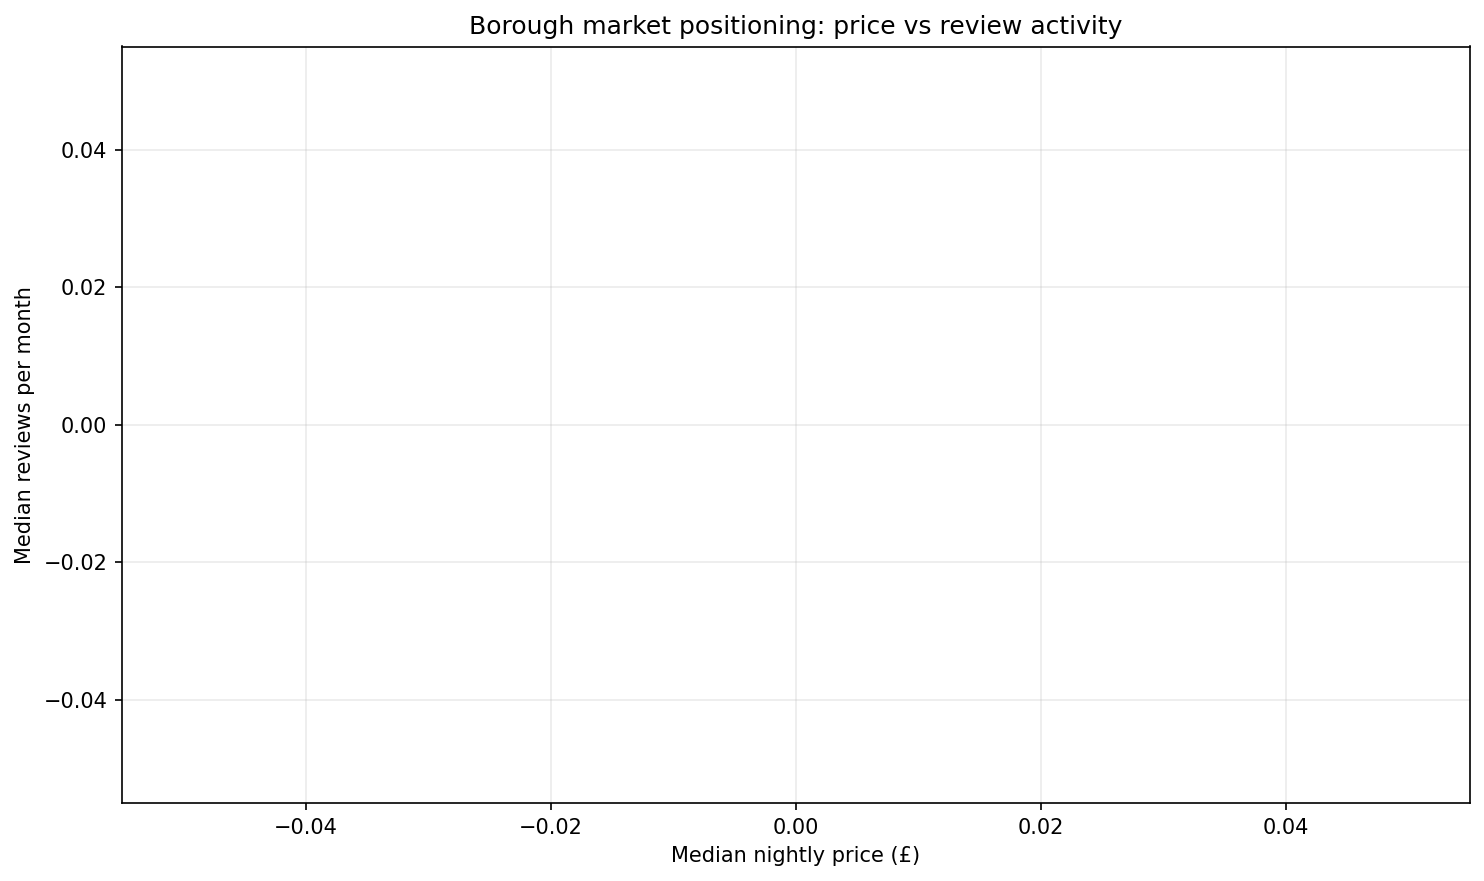

In [4]:
borough_col = "neighbourhood_group_cleansed"
borough_summary = work.groupby(borough_col).agg(
    listings=("id", "count"),
    median_price=("price", "median"),
    median_reviews_per_month=("reviews_per_month", "median"),
    median_availability=("availability_365", "median")
).dropna(subset=["median_price", "median_reviews_per_month"])
borough_summary = borough_summary[borough_summary.listings >= 30]
borough_summary = borough_summary.sort_values("listings", ascending=False).head(15).round(2).reset_index()
display(borough_summary)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(borough_summary.median_price, borough_summary.median_reviews_per_month,
           s=np.sqrt(borough_summary.listings) * 18, alpha=0.75)
for _, row in borough_summary.iterrows():
    ax.annotate(str(row[borough_col]), (row.median_price, row.median_reviews_per_month),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title("Borough market positioning: price vs review activity")
ax.set_xlabel("Median nightly price (£)")
ax.set_ylabel("Median reviews per month")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
